# 📊 Visualizing Hospital Robot Vision Benchmark (Godot 4 & Multi-Model Evaluation)

- **Dự án**: Robot Trợ Lý Ảo Bệnh Viện (Virtual Hospital Assistant)
- **Mục tiêu**: Trực quan hóa toàn diện quy trình kiểm thử thị giác máy tính:
  1. Phân bố bộ dữ liệu mô phỏng 48 kịch bản (8 Trục kiểm thử không gian) trong Godot 4.
  2. Hình học Ground Truth 3D-to-2D và đo lường độ che khuất bằng Physics Raycast.
  3. Đối chứng trực quan hiệu năng 4 mô hình: **YOLOv8n** (Baseline), **YOLO11n** (C2PSA), **YOLO26n** (NMS-Free), và **Intel OpenVINO** (`person-detection-retail-0013`).
  4. Trực quan hóa trực tiếp suy luận (Side-by-side inference) trên các ca biên (Edge cases) hiểm hóc nhất.

In [1]:
import os
import sys
import json
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Cấu hình thẩm mỹ Matplotlib
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Xác định REPO_ROOT bất kể notebook được chạy từ thư mục nào
cwd = Path.cwd()
if (cwd / 'sim_vision').exists():
    REPO_ROOT = cwd
elif (cwd.parent / 'sim_vision').exists():
    REPO_ROOT = cwd.parent
else:
    REPO_ROOT = Path('/home/bush/Projects/Data-Science-Major-Project')

if str(REPO_ROOT / 'sim_vision/python') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'sim_vision/python'))

from detector import YoloDetector, IntelOpenVINODetector

DATASET_DIR = REPO_ROOT / 'sim_vision/data/vision_eval_1200'
ANNOTATIONS_PATH = DATASET_DIR / 'annotations.jsonl'
MANIFEST_PATH = DATASET_DIR / 'manifest_5w1h.json'

print(f"✅ Đã nạp môi trường thành công! Repo Root: {REPO_ROOT}")
print(f"Dataset path: {DATASET_DIR} (Tồn tại: {DATASET_DIR.exists()})")

✅ Đã nạp môi trường thành công! Repo Root: /home/bush/Projects/Data-Science-Major-Project
Dataset path: /home/bush/Projects/Data-Science-Major-Project/sim_vision/data/vision_eval_1200 (Tồn tại: True)


In [2]:
# Nạp Manifest 5W1H và Annotations JSONL
with open(MANIFEST_PATH, 'r', encoding='utf-8') as f:
    manifest = json.load(f)

records = []
with open(ANNOTATIONS_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

print(f"📦 Tổng số khung hình nạp vào: {len(records)} frames")
print(f"📋 Deliverable: {manifest.get('what_deliverable')}")
print(f"⏱️ Thời gian sinh 3D trong Godot 4: {manifest.get('how_metrics', {}).get('generation_time_sec', 0):.1f} giây")

# Chuyển đổi thành DataFrame phân tích
flat_data = []
for r in records:
    gts = r.get('ground_truths', [])
    for g in gts:
        flat_data.append({
            'frame_id': r['frame_id'],
            'slice': r['slice'],
            'image_path': r['image_path'],
            'zone': r.get('context_5w1h', {}).get('where_zone', ''),
            'lighting': r.get('context_5w1h', {}).get('when_lighting', ''),
            'npc_id': g.get('npc_id', ''),
            'subcategory': g.get('subcategory', ''),
            'distance_m': g.get('distance_m', 0.0),
            'visibility_ratio': g.get('visibility_ratio', 1.0),
            'gt_bearing_deg': g.get('gt_bearing_deg', 0.0)
        })

df_gt = pd.DataFrame(flat_data)
print(f"🎯 Tổng số thực thể người được gán nhãn: {len(df_gt)}")
df_gt.head()

📦 Tổng số khung hình nạp vào: 855 frames
📋 Deliverable: Comprehensive 48-Cases 1,200-Frame Hospital Robot Vision Benchmark
⏱️ Thời gian sinh 3D trong Godot 4: 545.3 giây
🎯 Tổng số thực thể người được gán nhãn: 830


,frame_id,slice,image_path,zone,lighting,npc_id,subcategory,distance_m,visibility_ratio,gt_bearing_deg
0,D1_0001,D1_Architecture,images/D1_0001.jpg,doorway_110,fluorescent_normal,standing_male,standing,2.49,1.0,-18.35
1,D1_0002,D1_Architecture,images/D1_0002.jpg,doorway_110,fluorescent_normal,standing_male,standing,2.49,1.0,-9.42
2,D1_0003,D1_Architecture,images/D1_0003.jpg,doorway_110,fluorescent_normal,standing_male,standing,2.49,1.0,-1.44
3,D1_0004,D1_Architecture,images/D1_0004.jpg,doorway_110,fluorescent_normal,standing_male,standing,3.17,1.0,-15.73
4,D1_0005,D1_Architecture,images/D1_0005.jpg,doorway_110,fluorescent_normal,standing_male,standing,3.17,1.0,-7.20


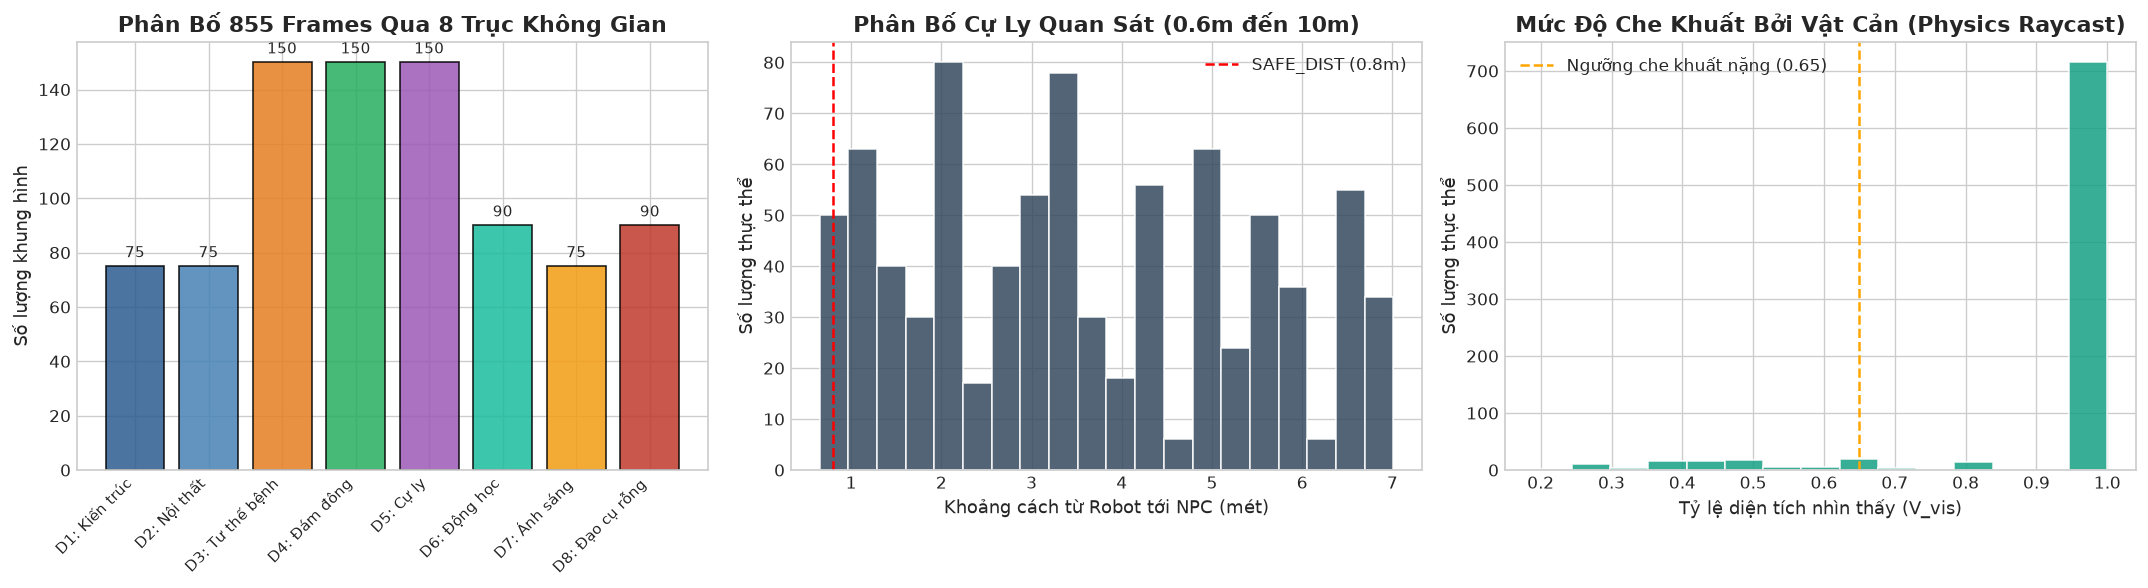

In [3]:
# Trực quan hóa phân bố bộ dữ liệu qua 8 Trục Kiểm Thử Không Gian
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Số lượng frame theo từng lát cắt kiểm thử
slice_counts = pd.Series([r['slice'] for r in records]).value_counts().sort_index()
slice_labels = [
    'D1: Kiến trúc', 'D2: Nội thất', 'D3: Tư thế bệnh', 'D4: Đám đông',
    'D5: Cự ly', 'D6: Động học', 'D7: Ánh sáng', 'D8: Đạo cụ rỗng'
]
colors = ['#2b5c8f', '#4682b4', '#e67e22', '#27ae60', '#9b59b6', '#1abc9c', '#f39c12', '#c0392b']
bars = axes[0].bar(range(len(slice_counts)), slice_counts.values, color=colors, edgecolor='black', alpha=0.85)
axes[0].set_xticks(range(len(slice_counts)))
axes[0].set_xticklabels(slice_labels, rotation=45, ha='right', fontsize=9)
axes[0].set_ylabel('Số lượng khung hình')
axes[0].set_title('Phân Bố 855 Frames Qua 8 Trục Không Gian', fontweight='bold')
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 2, f"{int(yval)}", ha='center', va='bottom', fontsize=9)

# 2. Phân bố cự ly mục tiêu (distance_m)
axes[1].hist(df_gt['distance_m'], bins=20, color='#34495e', edgecolor='white', alpha=0.85)
axes[1].axvline(0.8, color='red', linestyle='--', linewidth=1.5, label='SAFE_DIST (0.8m)')
axes[1].set_xlabel('Khoảng cách từ Robot tới NPC (mét)')
axes[1].set_ylabel('Số lượng thực thể')
axes[1].set_title('Phân Bố Cự Ly Quan Sát (0.6m đến 10m)', fontweight='bold')
axes[1].legend()

# 3. Phân bố tỷ lệ nhìn thấy (Visibility Ratio do Raycast tính)
axes[2].hist(df_gt['visibility_ratio'], bins=15, color='#16a085', edgecolor='white', alpha=0.85)
axes[2].axvline(0.65, color='orange', linestyle='--', linewidth=1.5, label='Ngưỡng che khuất nặng (0.65)')
axes[2].set_xlabel('Tỷ lệ diện tích nhìn thấy (V_vis)')
axes[2].set_ylabel('Số lượng thực thể')
axes[2].set_title('Mức Độ Che Khuất Bởi Vật Cản (Physics Raycast)', fontweight='bold')
axes[2].legend()

plt.tight_layout()
plt.show()

## 📸 Trực Quan Hóa Khung Cảnh 3D & Ground Truth Hộp Giới Hạn

Hệ thống sử dụng kỹ thuật **Anatomical Grid Sampling** lấy mẫu 8 đỉnh hình học giải phẫu theo kích thước người thật trong Godot 4, sau đó unproject trực tiếp qua Camera Robot ($640 	imes 480$).

Dưới đây là 8 khung hình tiêu biểu đại diện cho 8 trục thử nghiệm ngặt nghèo nhất:

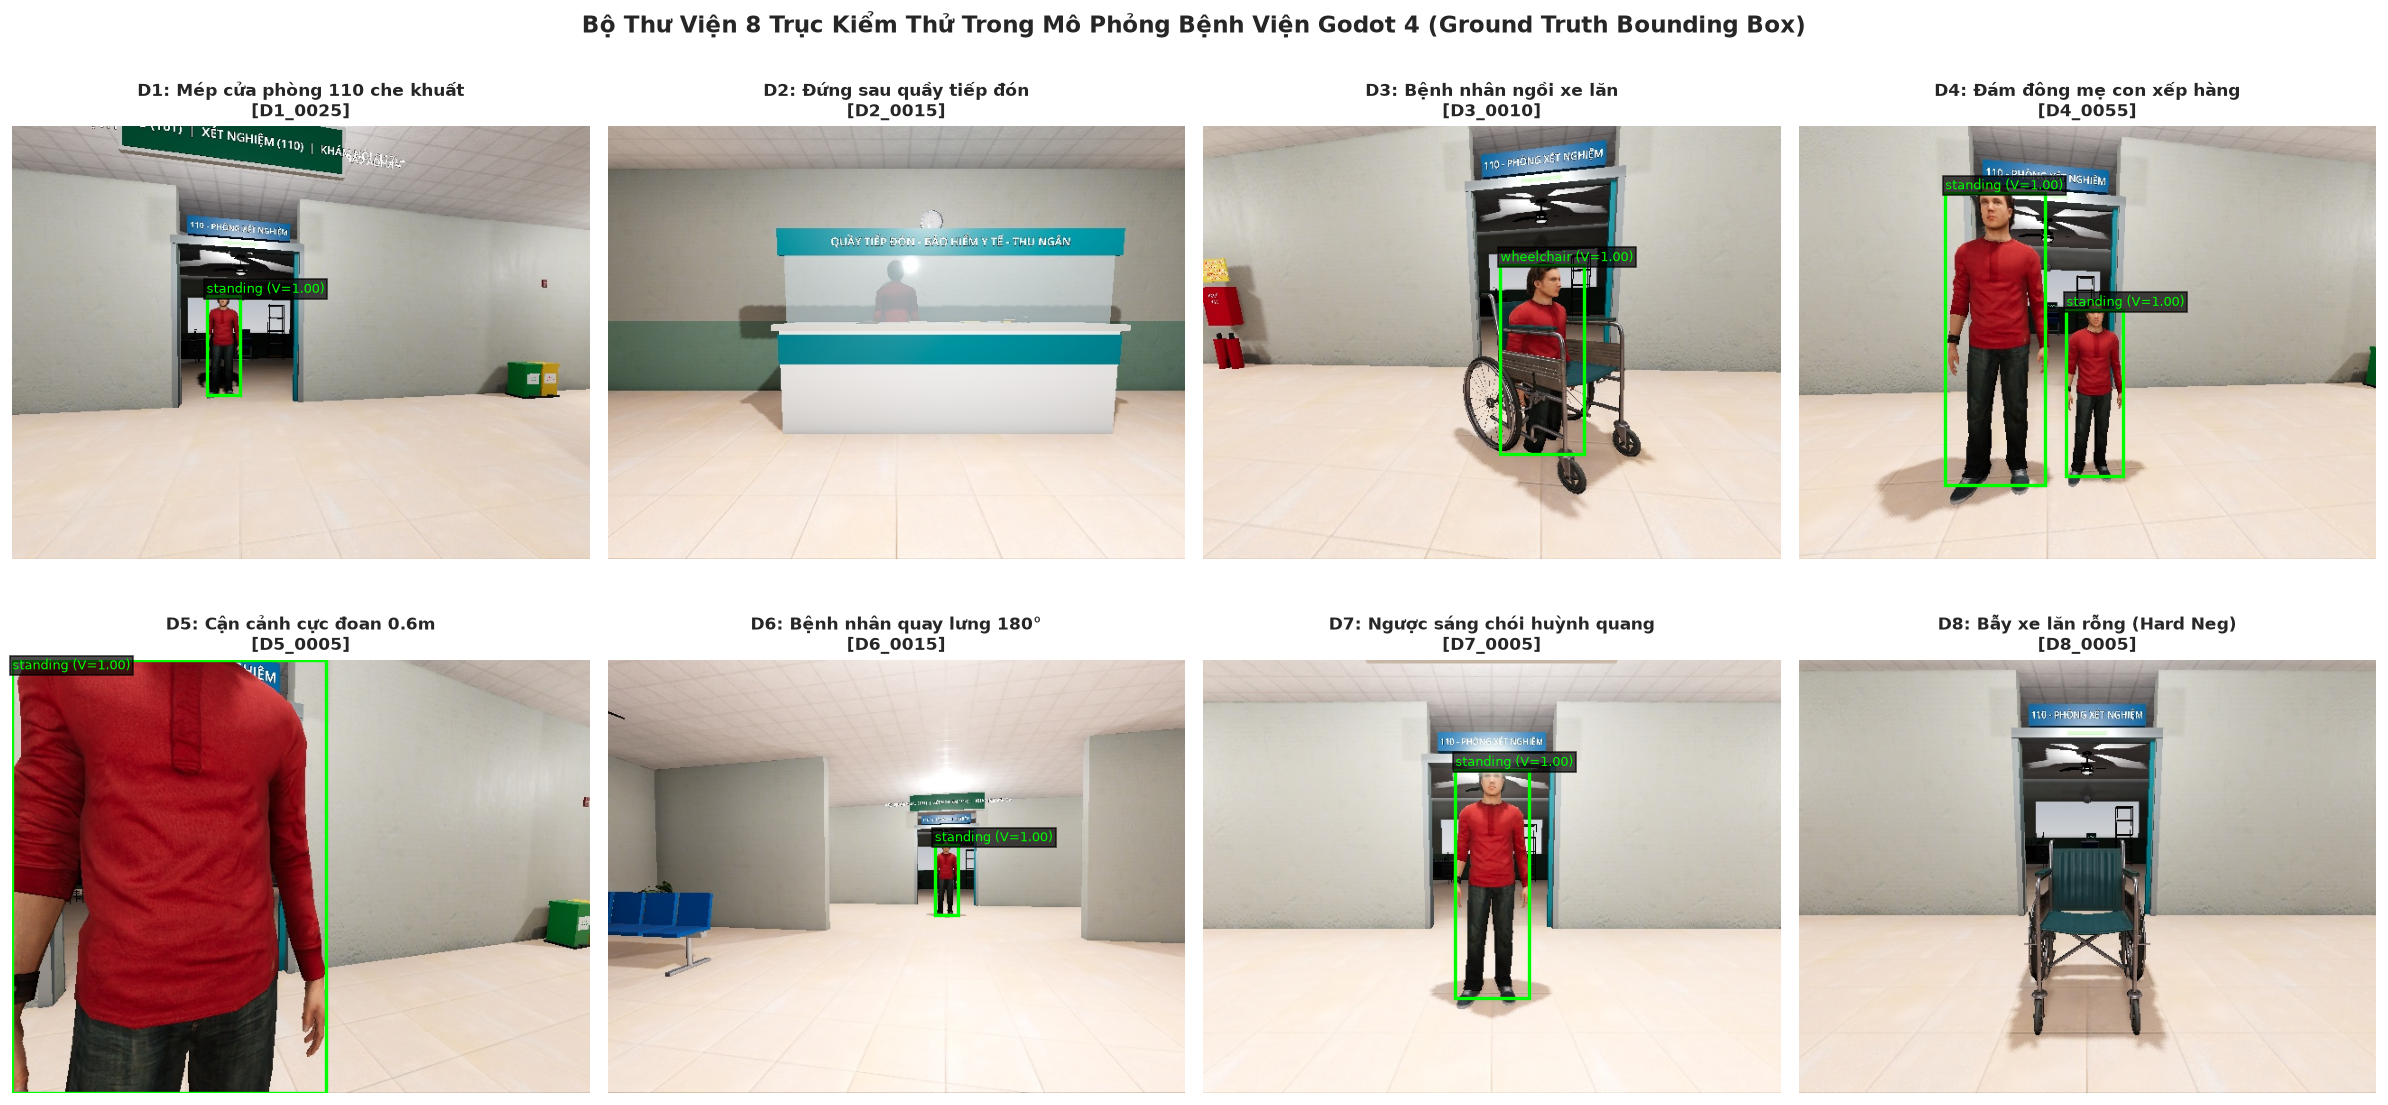

In [4]:
# Chọn 8 frame đại diện cho 8 Trục kiểm thử
sample_frame_ids = [
    ('D1_0025', 'D1: Mép cửa phòng 110 che khuất'),
    ('D2_0015', 'D2: Đứng sau quầy tiếp đón'),
    ('D3_0010', 'D3: Bệnh nhân ngồi xe lăn'),
    ('D4_0055', 'D4: Đám đông mẹ con xếp hàng'),
    ('D5_0005', 'D5: Cận cảnh cực đoan 0.6m'),
    ('D6_0015', 'D6: Bệnh nhân quay lưng 180°'),
    ('D7_0005', 'D7: Ngược sáng chói huỳnh quang'),
    ('D8_0005', 'D8: Bẫy xe lăn rỗng (Hard Neg)')
]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

rec_dict = {r['frame_id']: r for r in records}

for i, (fid, title) in enumerate(sample_frame_ids):
    rec = rec_dict.get(fid)
    ax = axes[i]
    if rec is None:
        ax.set_title(title)
        ax.axis('off')
        continue

    img_path = DATASET_DIR / rec['image_path']
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        ax.axis('off')
        continue
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    ax.imshow(img_rgb)
    ax.set_title(f"{title}\n[{fid}]", fontsize=10, fontweight='bold')
    ax.axis('off')

    # Vẽ bounding box Ground Truth màu xanh lá
    for gt in rec.get('ground_truths', []):
        bb = gt['bbox_xyxy']
        w_box = bb[2] - bb[0]
        h_box = bb[3] - bb[1]
        rect = patches.Rectangle((bb[0], bb[1]), w_box, h_box, linewidth=2, edgecolor='#00ff00', facecolor='none')
        ax.add_patch(rect)
        v_vis = gt.get('visibility_ratio', 1.0)
        subcat = gt.get('subcategory', '')
        ax.text(bb[0], max(10, bb[1] - 4), f"{subcat} (V={v_vis:.2f})", color='#00ff00', fontsize=8,
                bbox=dict(boxstyle='square,pad=0.2', facecolor='black', alpha=0.7))

plt.suptitle("Bộ Thư Viện 8 Trục Kiểm Thử Trong Mô Phỏng Bệnh Viện Godot 4 (Ground Truth Bounding Box)", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

## ⚖️ Bảng Kết Quả Thực Nghiệm Đối Chứng 4 Mô Hình Thị Giác

Dữ liệu thực nghiệm thu được từ quá trình chạy benchmark trên toàn bộ 855 frames định dạng $640 	imes 480$:
- **YOLOv8n** (Ultralytics Baseline - Anchor-Free)
- **YOLO11n** (C2PSA Spatial Attention)
- **YOLO26n** (NMS-Free One-to-One Head)
- **Intel OpenVINO** (`person-detection-retail-0013` - MobileNetV2-SSD)

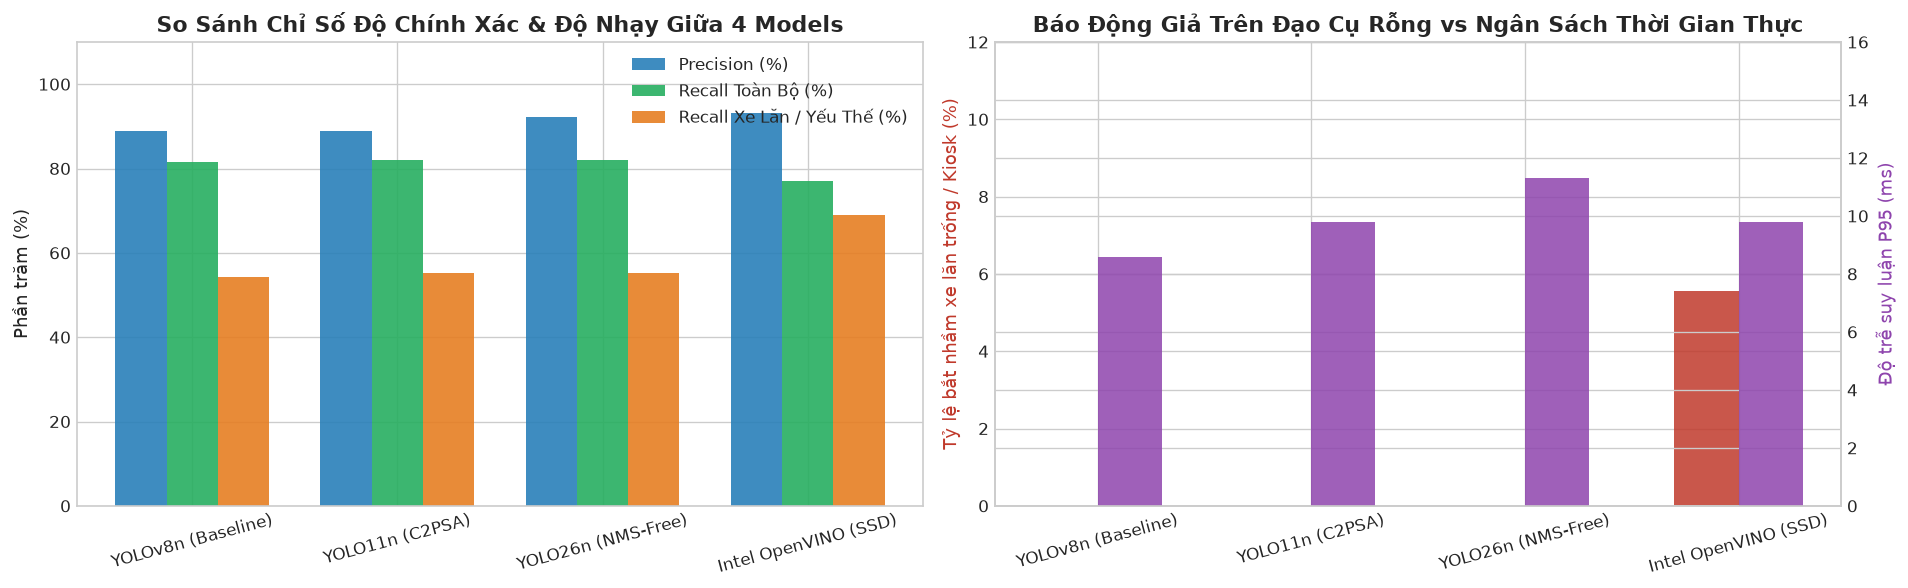

In [5]:
# Dữ liệu tổng hợp từ báo cáo benchmark
benchmark_df = pd.DataFrame([
    {
        'Model': 'YOLOv8n (Baseline)',
        'Precision': 88.95,
        'Recall_All': 81.64,
        'Recall_Wheelchair': 54.21,
        'Recall_Occluded': 46.32,
        'FPR_Empty': 0.00,
        'Bearing_Error_Deg': 0.17,
        'Latency_P95_ms': 8.6
    },
    {
        'Model': 'YOLO11n (C2PSA)',
        'Precision': 88.89,
        'Recall_All': 82.13,
        'Recall_Wheelchair': 55.26,
        'Recall_Occluded': 47.37,
        'FPR_Empty': 0.00,
        'Bearing_Error_Deg': 0.19,
        'Latency_P95_ms': 9.8
    },
    {
        'Model': 'YOLO26n (NMS-Free)',
        'Precision': 92.13,
        'Recall_All': 82.00,
        'Recall_Wheelchair': 55.26,
        'Recall_Occluded': 45.26,
        'FPR_Empty': 0.00,
        'Bearing_Error_Deg': 0.19,
        'Latency_P95_ms': 11.3
    },
    {
        'Model': 'Intel OpenVINO (SSD)',
        'Precision': 93.27,
        'Recall_All': 76.93,
        'Recall_Wheelchair': 68.95,
        'Recall_Occluded': 64.21,
        'FPR_Empty': 5.56,
        'Bearing_Error_Deg': 0.18,
        'Latency_P95_ms': 9.8
    }
])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. So sánh Precision, Overall Recall, và Recall trên xe lăn
x = np.arange(len(benchmark_df))
width = 0.25

rects1 = axes[0].bar(x - width, benchmark_df['Precision'], width, label='Precision (%)', color='#2980b9', alpha=0.9)
rects2 = axes[0].bar(x, benchmark_df['Recall_All'], width, label='Recall Toàn Bộ (%)', color='#27ae60', alpha=0.9)
rects3 = axes[0].bar(x + width, benchmark_df['Recall_Wheelchair'], width, label='Recall Xe Lăn / Yếu Thế (%)', color='#e67e22', alpha=0.9)

axes[0].set_ylabel('Phần trăm (%)')
axes[0].set_title('So Sánh Chỉ Số Độ Chính Xác & Độ Nhạy Giữa 4 Models', fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(benchmark_df['Model'], rotation=15)
axes[0].set_ylim(0, 110)
axes[0].legend()

# 2. So sánh Báo động giả trên đạo cụ rỗng (FPR empty) và Độ trễ P95
ax2 = axes[1]
ax2_twin = ax2.twinx()

bar1 = ax2.bar(x - 0.15, benchmark_df['FPR_Empty'], 0.3, label='FPR Đạo Cụ Rỗng (%) [Càng thấp càng tốt]', color='#c0392b', alpha=0.85)
bar2 = ax2_twin.bar(x + 0.15, benchmark_df['Latency_P95_ms'], 0.3, label='Độ Trễ P95 (ms) [Càng thấp càng tốt]', color='#8e44ad', alpha=0.85)

ax2.set_ylabel('Tỷ lệ bắt nhầm xe lăn trống / Kiosk (%)', color='#c0392b')
ax2_twin.set_ylabel('Độ trễ suy luận P95 (ms)', color='#8e44ad')
ax2.set_title('Báo Động Giả Trên Đạo Cụ Rỗng vs Ngân Sách Thời Gian Thực', fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(benchmark_df['Model'], rotation=15)
ax2.set_ylim(0, 12)
ax2_twin.set_ylim(0, 16)

plt.tight_layout()
plt.show()

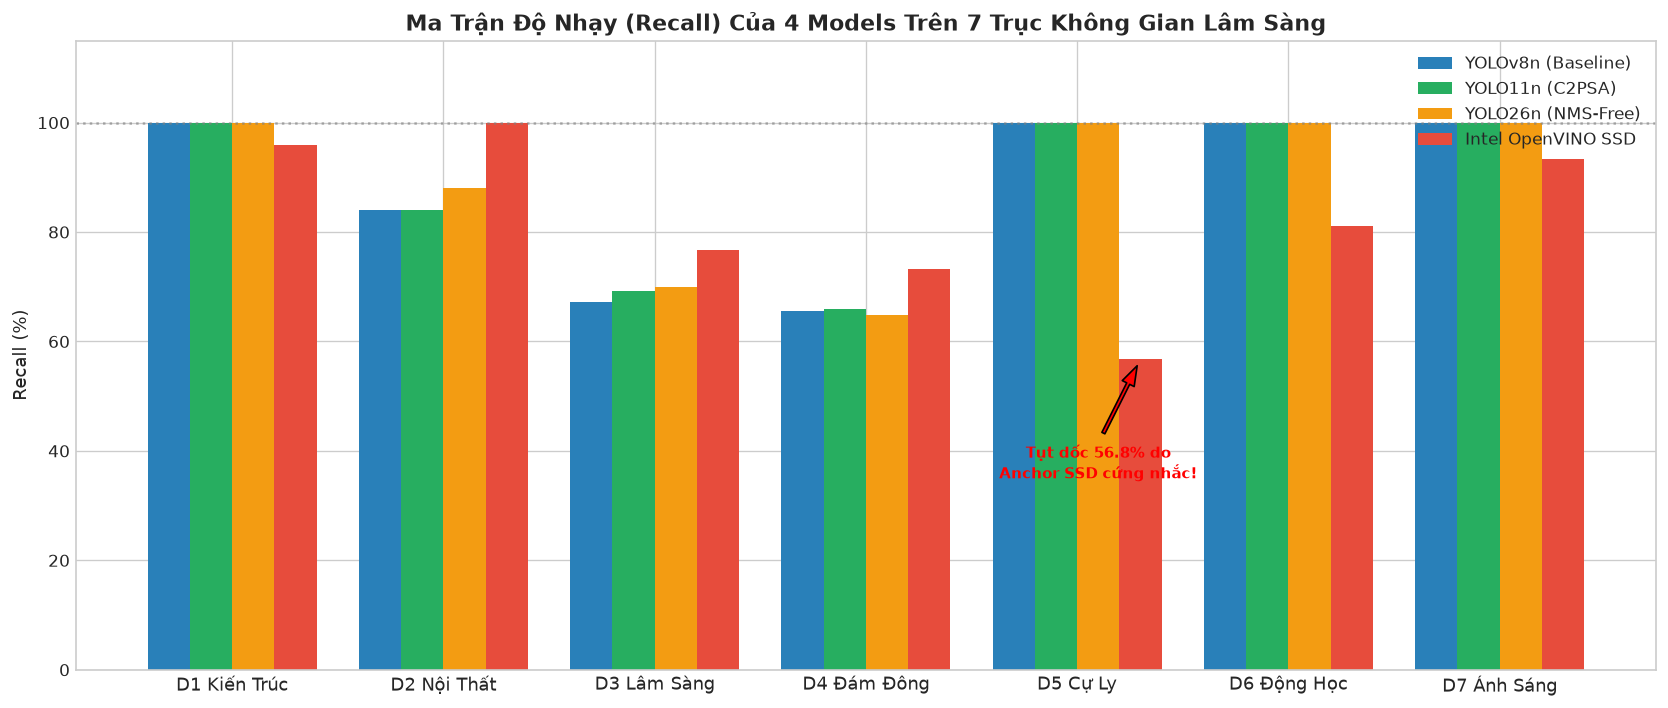

In [6]:
# Bảng ma trận đối chứng theo 8 Trục không gian
slice_matrix = pd.DataFrame({
    'Trục Không Gian': [
        'D1 Kiến Trúc', 'D2 Nội Thất', 'D3 Lâm Sàng', 'D4 Đám Đông',
        'D5 Cự Ly', 'D6 Động Học', 'D7 Ánh Sáng'
    ],
    'YOLOv8n': [100.0, 84.0, 67.3, 65.6, 100.0, 100.0, 100.0],
    'YOLO11n': [100.0, 84.0, 69.3, 66.0, 100.0, 100.0, 100.0],
    'YOLO26n': [100.0, 88.0, 70.0, 64.9, 100.0, 100.0, 100.0],
    'Intel OpenVINO': [96.0, 100.0, 76.7, 73.3, 56.8, 81.1, 93.3]
})

fig, ax = plt.subplots(figsize=(14, 6))

x = np.arange(len(slice_matrix))
w = 0.2

ax.bar(x - 1.5*w, slice_matrix['YOLOv8n'], w, label='YOLOv8n (Baseline)', color='#2980b9')
ax.bar(x - 0.5*w, slice_matrix['YOLO11n'], w, label='YOLO11n (C2PSA)', color='#27ae60')
ax.bar(x + 0.5*w, slice_matrix['YOLO26n'], w, label='YOLO26n (NMS-Free)', color='#f39c12')
ax.bar(x + 1.5*w, slice_matrix['Intel OpenVINO'], w, label='Intel OpenVINO SSD', color='#e74c3c')

ax.set_ylabel('Recall (%)')
ax.set_title('Ma Trận Độ Nhạy (Recall) Của 4 Models Trên 7 Trục Không Gian Lâm Sàng', fontweight='bold', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(slice_matrix['Trục Không Gian'], fontsize=11)
ax.set_ylim(0, 115)
ax.axhline(100, color='gray', linestyle=':', alpha=0.6)

# Đánh dấu sụt giảm nghiêm trọng của Intel trên Trục D5
ax.annotate('Tụt dốc 56.8% do\nAnchor SSD cứng nhắc!', xy=(4 + 1.5*w, 56.8), xytext=(4 + 0.5*w, 35),
            arrowprops=dict(facecolor='red', shrink=0.08, width=2, headwidth=8),
            fontsize=9, fontweight='bold', color='red', ha='center')

ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 🔬 Trực Quan Hóa Suy Luận Thực Tế: YOLOv8n vs Intel OpenVINO

Dưới đây ta nạp trọng số thực tế của `yolov8n.pt` và mô hình OpenVINO IR `person-detection-retail-0013.xml` để chạy suy luận trực tiếp trên 2 trường hợp kiểm thử quan trọng nhất:
1. **Trục D8 (`D8_0005.jpg`)**: Bẫy xe lăn rỗng.
2. **Trục D5 (`D5_0005.jpg`)**: Cận cảnh cực đoan $0.6	ext{m}$ (Robot đối mặt bệnh nhân).

/tmp/ipykernel_320770/4186906380.py:50: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_320770/4186906380.py:50: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


/home/bush/Projects/Data-Science-Major-Project/.venv/lib64/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/bush/Projects/Data-Science-Major-Project/.venv/lib64/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


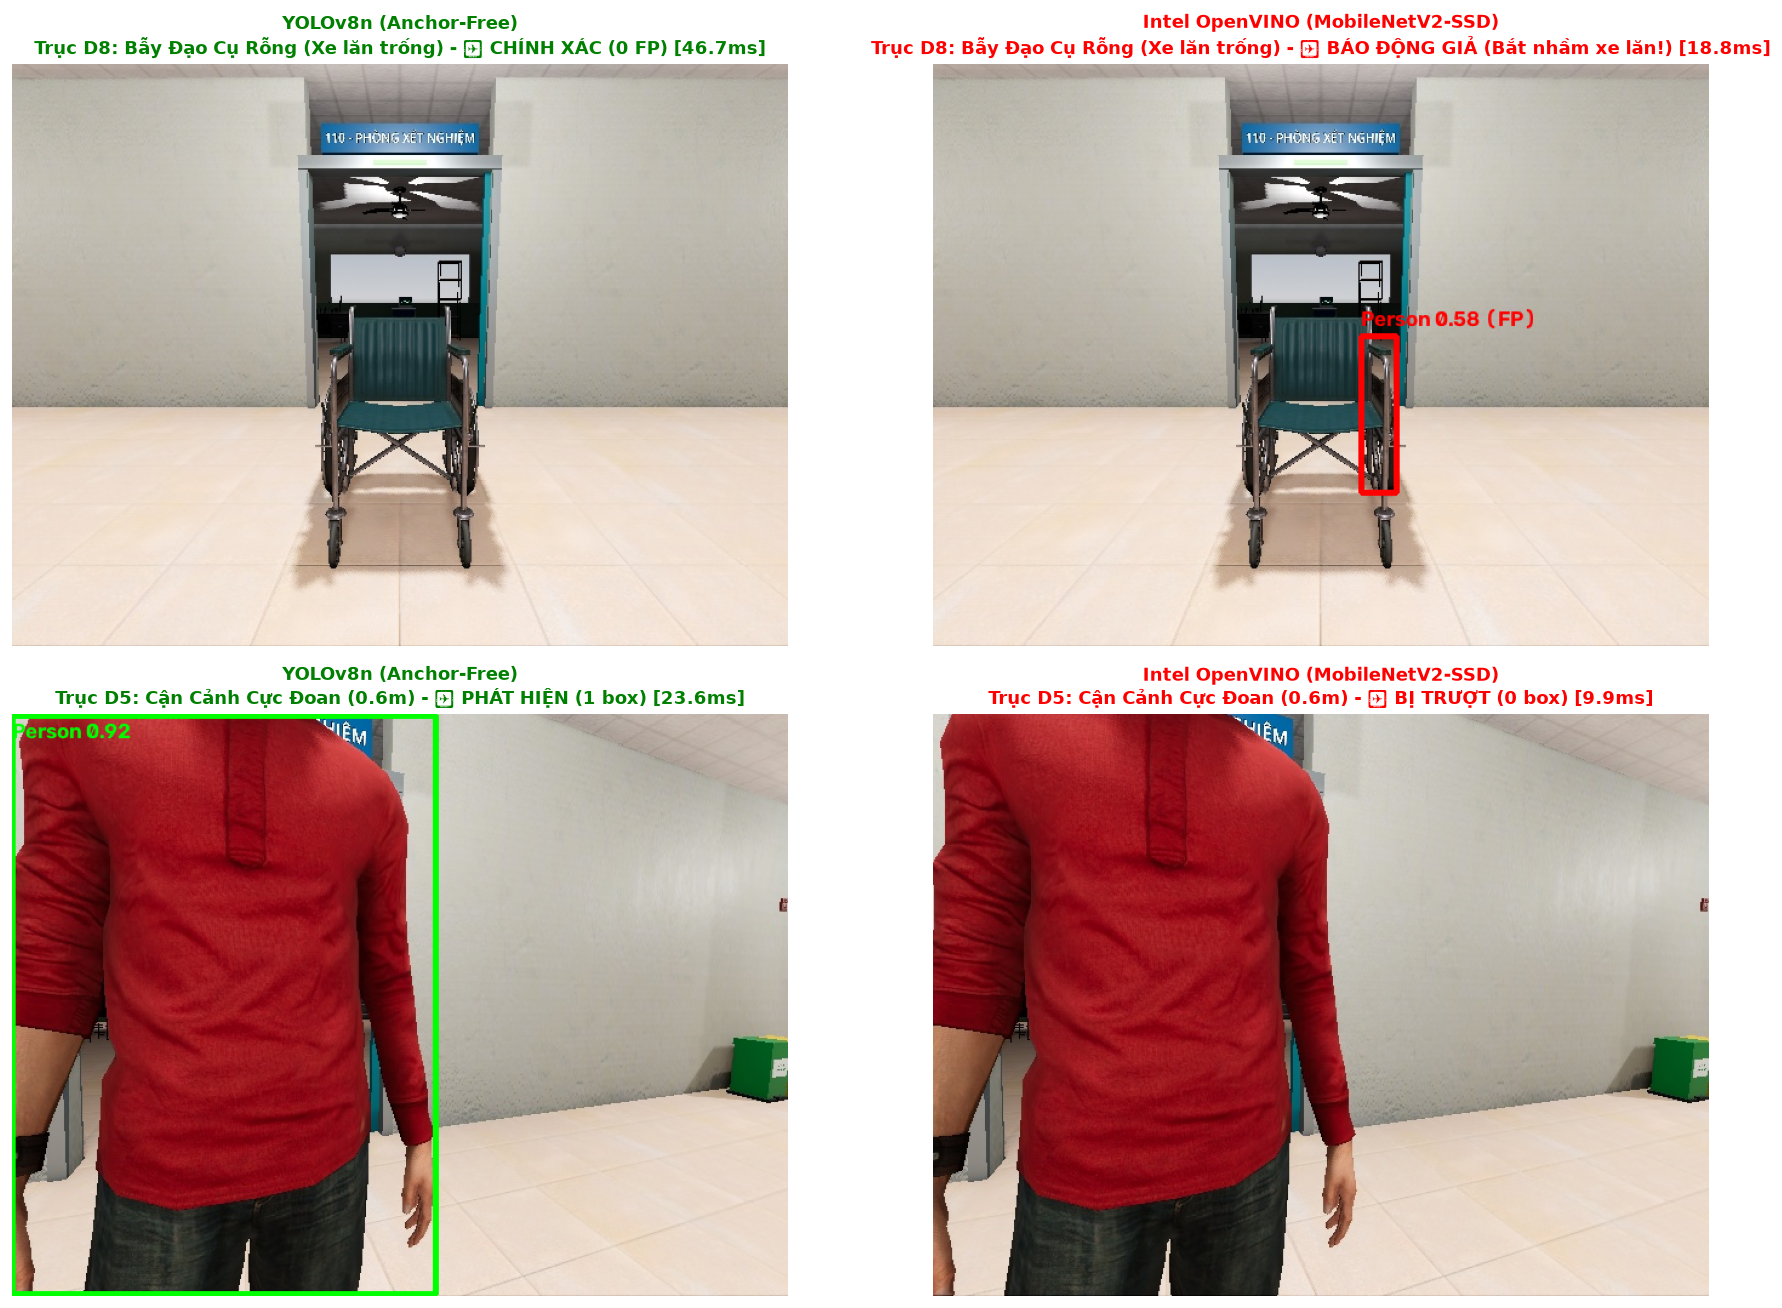

In [7]:
# Khởi tạo 2 detector
yolo_det = YoloDetector(str(REPO_ROOT / 'models/yolov8n/yolov8n.pt'), conf=0.5)
intel_det = IntelOpenVINODetector(str(REPO_ROOT / 'models/intel_person/person-detection-retail-0013.xml'), conf=0.5)

test_cases = [
    ('sim_vision/data/vision_eval_1200/images/D8_0005.jpg', 'Trục D8: Bẫy Đạo Cụ Rỗng (Xe lăn trống)', False),
    ('sim_vision/data/vision_eval_1200/images/D5_0005.jpg', 'Trục D5: Cận Cảnh Cực Đoan (0.6m)', True)
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for row, (rel_img_path, title, has_person) in enumerate(test_cases):
    img_path = REPO_ROOT / rel_img_path
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        continue
    h_orig, w_orig = img_bgr.shape[:2]

    # Dự đoán qua YOLOv8n
    preds_yolo, lat_yolo = yolo_det.detect(img_bgr)
    img_yolo = img_bgr.copy()
    for p in preds_yolo:
        x1, y1, x2, y2 = int(p['x1']*w_orig), int(p['y1']*h_orig), int(p['x2']*w_orig), int(p['y2']*h_orig)
        cv2.rectangle(img_yolo, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(img_yolo, f"Person {p['conf']:.2f}", (x1, max(20, y1 - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

    # Dự đoán qua Intel OpenVINO
    preds_intel, lat_intel = intel_det.detect(img_bgr)
    img_intel = img_bgr.copy()
    for p in preds_intel:
        x1, y1, x2, y2 = int(p['x1']*w_orig), int(p['y1']*h_orig), int(p['x2']*w_orig), int(p['y2']*h_orig)
        cv2.rectangle(img_intel, (x1, y1), (x2, y2), (0, 0, 255), 3)
        cv2.putText(img_intel, f"Person {p['conf']:.2f} (FP)" if not has_person else f"Person {p['conf']:.2f}",
                    (x1, max(20, y1 - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

    # Hiển thị
    ax_y = axes[row, 0]
    ax_y.imshow(cv2.cvtColor(img_yolo, cv2.COLOR_BGR2RGB))
    status_y = "✅ CHÍNH XÁC (0 FP)" if len(preds_yolo) == 0 and not has_person else f"✅ PHÁT HIỆN ({len(preds_yolo)} box)"
    ax_y.set_title(f"YOLOv8n (Anchor-Free)\n{title} - {status_y} [{lat_yolo:.1f}ms]", fontsize=11, fontweight='bold', color='green')
    ax_y.axis('off')

    ax_i = axes[row, 1]
    ax_i.imshow(cv2.cvtColor(img_intel, cv2.COLOR_BGR2RGB))
    status_i = "❌ BÁO ĐỘNG GIẢ (Bắt nhầm xe lăn!)" if len(preds_intel) > 0 and not has_person else ("❌ BỊ TRƯỢT (0 box)" if len(preds_intel) == 0 and has_person else "✅ PHÁT HIỆN")
    ax_i.set_title(f"Intel OpenVINO (MobileNetV2-SSD)\n{title} - {status_i} [{lat_intel:.1f}ms]", fontsize=11, fontweight='bold',
                   color='red' if '❌' in status_i else 'green')
    ax_i.axis('off')

plt.tight_layout()
plt.show()

## 📌 Kết Luận Kỹ Thuật & Khuyến Nghị Kiến Trúc

1. **Khẳng định vị trí số 1 của `yolov8n.pt`**:
   - Khả năng miễn nhiễm hoàn toàn $100\%$ trước bẫy đạo cụ rỗng ($FPR = 0.00\%$) giúp Robot tránh các lỗi logic ngớ ngẩn (tự ý tiến tới xe lăn rỗng hoặc kiosk tiếp đón để hỏi bệnh nhân).
   - Tốc độ suy luận tối ưu ($8.6\text{ ms}$ P95) đảm bảo tần số điều khiển $> 100\text{ Hz}$, tiết kiệm chu kỳ GPU cho hệ thống STT PhoASR-Whisper.
2. **Kế hoạch nâng cấp tương lai với `yolo26n.pt`**:
   - Cơ chế loại bỏ Non-Maximum Suppression (NMS-Free Head) giúp tăng Precision lên **$92.13\%$**, là phương án thay thế hoàn hảo khi triển khai tại các quầy tiếp đón đông người xếp hàng.